# CareerScope: initial data exploration (Phase 2)

This notebook explores the **processed** tables in `data/processed`, produced by `clean_data.py` and checked by `validate_data.py`. It is descriptive only: it shows what the data contains and how complete it is. It does not predict anything and does not claim that one measure causes another.

Rules applied throughout (see `docs/project_scope.md`):
- **D1 and D11:** a value is "reliable" if its grade is A, B, C or D, or if it is an exact value with no grade (0443 zeros and 100% totals; every 0417 value). Grade E is excluded from rankings. F, suppressed and unavailable cells have no value.
- **D9:** trends start at 2015-04. **D13:** values flagged `is_suspect` are excluded.
- Offered wages (0444, 0443) are advertised minimums. Employee wages (0417) are actual wages in current (not inflation-adjusted) dollars. They are never combined in one series.

Run the cells from top to bottom. Charts are saved to `docs/figures/`.

In [1]:
from pathlib import Path
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
assert (PROC / "fact_14100444.csv").exists(), f"No processed files in {PROC}. Run src/clean_data.py first."
print("Project root:", ROOT)

Project root: C:\Users\ethan\Projects\CareerScope


In [2]:
def read(name, **kwargs):
    return pd.read_csv(PROC / name, keep_default_na=False, na_values=[""], low_memory=False, **kwargs)


geo = read("dim_geography.csv", dtype={"sgc_code": str})
noc = read("dim_occupation.csv", dtype={"noc_code": str})
char = read("dim_characteristic.csv")
f444 = read("fact_14100444.csv")
f443 = read("fact_14100443.csv")
f417 = read("fact_14100417.csv", dtype={"noc417_code": str})
av444 = read("availability_14100444.csv")
for frame in (f444, f443, f417, av444):
    frame["period_start"] = pd.to_datetime(frame["period_start"])

geo_name = geo.set_index("geo_id")["geo_name"]
char_title = char.set_index("char_id")["char_title"]

print({"0444 rows": len(f444), "0443 rows": len(f443), "0417 rows": len(f417)})
print("Suspect-flagged rows:", {"0444": int(f444["is_suspect"].sum()),
                                "0443": int(f443["is_suspect"].sum()),
                                "0417": int(f417["is_suspect"].sum())})

{'0444 rows': 1250123, '0443 rows': 3344531, '0417 rows': 149214}
Suspect-flagged rows: {'0444': 0, '0443': 17, '0417': 0}


In [3]:
LATEST = f444["period_start"].max()
QUARTERS = pd.date_range("2015-01-01", LATEST, freq="QS-JAN")
RELIABLE_GRADES = {"A", "B", "C", "D", "NONE"}   # NONE = exact value with no grade


def reliable(frame):
    """D1, D11, D13: grades A to D or ungraded exact values, and not flagged as suspect."""
    return frame[frame["quality_grade"].isin(RELIABLE_GRADES) & ~frame["is_suspect"]]


def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")


GAP = (pd.Timestamp("2020-04-01"), pd.Timestamp("2020-10-01"))   # Q2 and Q3 2020 do not exist
print("Latest quarter:", LATEST.date())

Latest quarter: 2026-04-01


## 1. How much of the 0444 grid actually has a value?

Every combination of geography, occupation, quarter and measure exists as a row in the raw table, but most rows are empty. This is the share of those cells with a published value, by quarter.

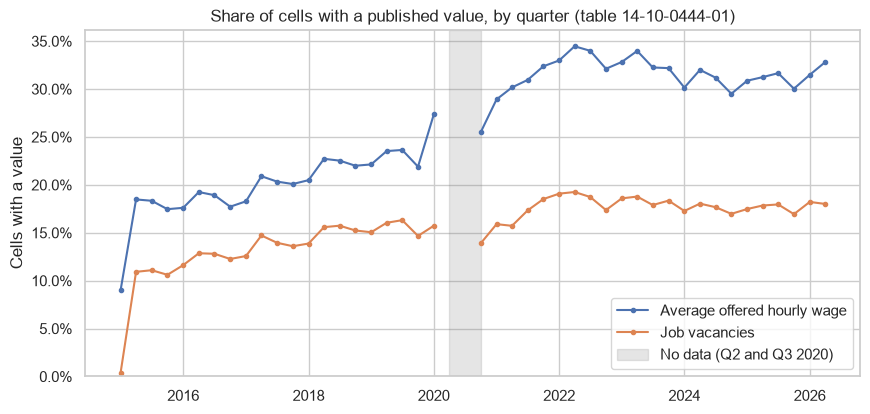

measure     job_vacancies  offered_wage_avg
2015-01-01          0.004             0.090
2015-04-01          0.109             0.185
2015-07-01          0.111             0.183
2015-10-01          0.106             0.175
2016-01-01          0.116             0.176
2016-04-01          0.129             0.192


In [4]:
total = av444.groupby(["period_start", "measure"])["n_cells"].sum()
with_value = av444[av444["status_group"] == "value"].groupby(["period_start", "measure"])["n_cells"].sum()
share = (with_value / total).unstack("measure").reindex(QUARTERS)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(share.index, share["offered_wage_avg"], marker="o", ms=3, label="Average offered hourly wage")
ax.plot(share.index, share["job_vacancies"], marker="o", ms=3, label="Job vacancies")
ax.axvspan(*GAP, color="grey", alpha=0.2, label="No data (Q2 and Q3 2020)")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(bottom=0)
ax.set_title("Share of cells with a published value, by quarter (table 14-10-0444-01)")
ax.set_ylabel("Cells with a value")
ax.legend(loc="lower right")
save(fig, "01_availability_by_quarter.png")
plt.show()

print(share.round(3).head(6).to_string())

## 2. Quality grades: wages versus vacancies

Statistics Canada grades each published estimate from A (excellent) to E (use with caution). F values are not published, so they have no value in the table.

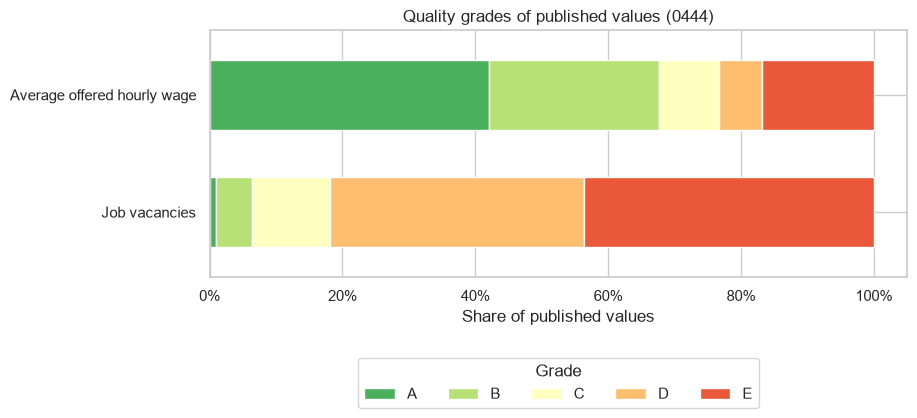

quality_grade                    A      B      C      D      E
measure                                                       
Job vacancies                0.010  0.053  0.117  0.383  0.436
Average offered hourly wage  0.421  0.255  0.091  0.064  0.169


In [5]:
grades = list("ABCDE")
mix = f444.groupby(["measure", "quality_grade"]).size().unstack().reindex(columns=grades).fillna(0)
mix = mix.div(mix.sum(axis=1), axis=0)
names = {"offered_wage_avg": "Average offered hourly wage", "job_vacancies": "Job vacancies"}

fig, ax = plt.subplots(figsize=(9, 3.2))
mix.rename(index=names).plot(kind="barh", stacked=True, ax=ax, width=0.6,
                             color=sns.color_palette("RdYlGn", 5)[::-1])
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Share of published values")
ax.set_ylabel("")
ax.set_title("Quality grades of published values (0444)")
ax.legend(title="Grade", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.3))
save(fig, "02_grade_mix.png")
plt.show()

print(mix.rename(index=names).round(3).to_string())

## 3. Where is there enough reliable data? (rule D10)

For the latest quarter, the share of occupation groups at each level that have a **reliable** value, by province or territory. Level 1 is the broad category (10 groups) and level 5 is the unit group (516 groups). Under D10, a province-by-occupation view is shown only where at least 50% of cells qualify.

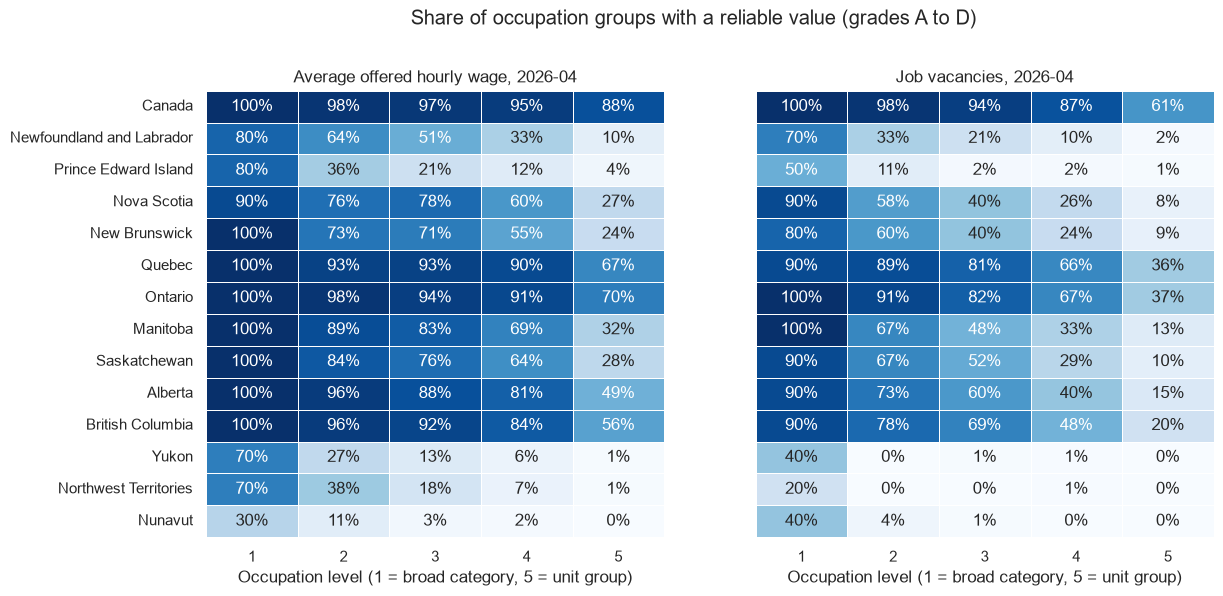

Number of the 14 geographies (Canada plus 13 provinces/territories) meeting the 50% rule:
noc_level          1   2   3  4  5
measure                           
job_vacancies     11   9   6  3  1
offered_wage_avg  13  10  10  9  4


In [6]:
levels = noc[noc["noc_level"] > 0].groupby("noc_level").size()
base = f444[(f444["period_start"] == LATEST) & (f444["geo_id"] <= 14)]
cells = (reliable(base).merge(noc[["noc_id", "noc_level"]], on="noc_id")
         .query("noc_level > 0")
         .groupby(["measure", "geo_id", "noc_level"]).size().rename("n").reset_index())
cells["share"] = cells["n"] / cells["noc_level"].map(levels)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), sharey=True)
panels = [("offered_wage_avg", "Average offered hourly wage"), ("job_vacancies", "Job vacancies")]
for ax, (measure, title) in zip(axes, panels):
    grid = (cells[cells["measure"] == measure]
            .pivot(index="geo_id", columns="noc_level", values="share")
            .reindex(index=range(1, 15), columns=range(1, 6)).fillna(0))
    grid.index = grid.index.map(geo_name)
    sns.heatmap(grid, annot=True, fmt=".0%", vmin=0, vmax=1, cmap="Blues",
                cbar=False, linewidths=0.5, ax=ax)
    ax.set_title(f"{title}, {LATEST:%Y-%m}")
    ax.set_xlabel("Occupation level (1 = broad category, 5 = unit group)")
    ax.set_ylabel("")
fig.suptitle("Share of occupation groups with a reliable value (grades A to D)", y=1.02)
save(fig, "03_reliable_coverage_heatmap.png")
plt.show()

meets = (cells[cells["share"] >= 0.5].groupby(["measure", "noc_level"])["geo_id"]
         .nunique().unstack(fill_value=0))
print("Number of the 14 geographies (Canada plus 13 provinces/territories) meeting the 50% rule:")
print(meets.to_string())

## 4. Offered wages across Canadian unit groups

Canada-wide, latest quarter, unit-group level (5-digit), reliable values only. The summary below is **unweighted** across occupations, so it is not the national average wage.

Unit groups with a reliable offered wage: 453 of 516
count    453.00
mean      33.17
std       11.73
min       17.45
25%       24.75
50%       31.10
75%       38.45
max       94.50


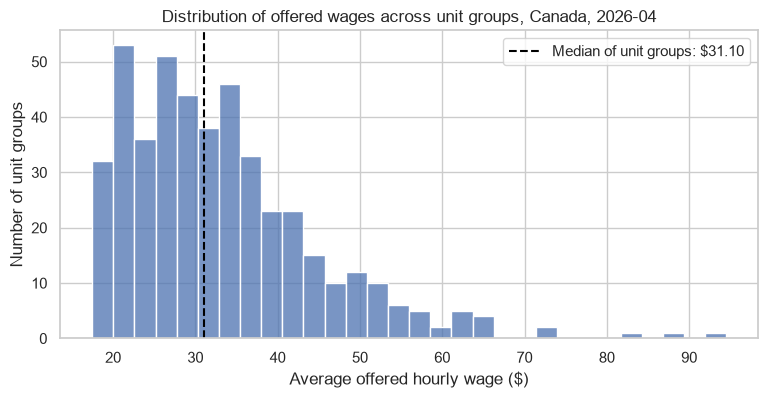


Highest offered wages:
noc_code                                                                                       noc_title  offered_wage quality_grade  vacancies
   00012                         Senior managers - financial, communications and other business services         94.50             A      325.0
   00015                        Senior managers - construction, transportation, production and utilities         87.50             B        NaN
   31110                                                                                        Dentists         83.15             C      295.0
   00013 Senior managers - health, education, social and community services and membership organizations         73.90             C        NaN
   00014                                        Senior managers - trade, broadcasting and other services         72.65             C        NaN
   80010                                            Managers in natural resources production and fishing        

In [7]:
canada = reliable(f444[(f444["period_start"] == LATEST) & (f444["geo_id"] == 1)]).merge(
    noc[["noc_id", "noc_code", "noc_title", "noc_level"]], on="noc_id")
wage5 = canada[(canada["measure"] == "offered_wage_avg") & (canada["noc_level"] == 5)]
vac5 = canada[(canada["measure"] == "job_vacancies") & (canada["noc_level"] == 5)]

print(f"Unit groups with a reliable offered wage: {len(wage5)} of {int(levels[5])}")
print(wage5["value"].describe().round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(wage5["value"], bins=30, ax=ax)
median = wage5["value"].median()
ax.axvline(median, ls="--", color="black", label=f"Median of unit groups: ${median:.2f}")
ax.set_xlabel("Average offered hourly wage ($)")
ax.set_ylabel("Number of unit groups")
ax.set_title(f"Distribution of offered wages across unit groups, Canada, {LATEST:%Y-%m}")
ax.legend()
save(fig, "04_wage_distribution.png")
plt.show()

table = wage5.rename(columns={"value": "offered_wage"}).merge(
    vac5[["noc_id", "value"]].rename(columns={"value": "vacancies"}), on="noc_id", how="left")
show = ["noc_code", "noc_title", "offered_wage", "quality_grade", "vacancies"]
print("\nHighest offered wages:")
print(table.nlargest(10, "offered_wage")[show].to_string(index=False))
print("\nLowest offered wages:")
print(table.nsmallest(10, "offered_wage")[show].to_string(index=False))

## 5. Wage and vacancies together (descriptive)

Each point is a unit group with both a reliable wage and a reliable vacancy count. The rank correlation is a descriptive summary only. These unit groups are not a random sample and vacancy counts are rounded estimates, so no significance test is reported. A high-wage, high-vacancy group is not a recommendation: vacancies measure reported openings, not a chance of being hired.

Unit groups plotted: 312. Spearman rank correlation: -0.27


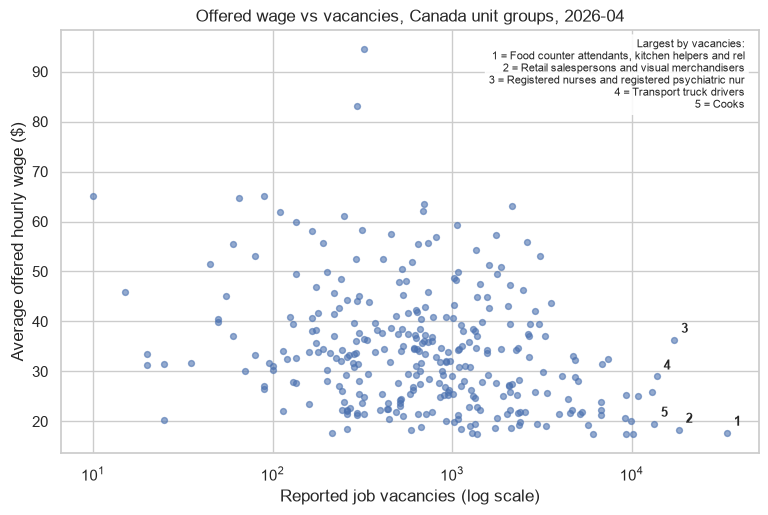


65 unit groups are at or above the median on both measures. Largest by vacancies:
noc_code                                                  noc_title  wage  vacancies
   31301        Registered nurses and registered psychiatric nurses 36.35    17275.0
   72310                                                 Carpenters 33.00     4695.0
   21232                        Software developers and programmers 43.65     3545.0
   11100                         Financial auditors and accountants 37.10     3290.0
   10010                                         Financial managers 53.15     3095.0
   72401                             Heavy-duty equipment mechanics 39.40     3045.0
   21222                            Information systems specialists 42.15     2910.0
   11201 Professional occupations in business management consulting 39.45     2705.0
   73400                                  Heavy equipment operators 32.90     2695.0
   62100              Technical sales specialists - wholesale trade

In [12]:
both = (wage5[["noc_id", "noc_code", "noc_title", "value"]].rename(columns={"value": "wage"})
        .merge(vac5[["noc_id", "value"]].rename(columns={"value": "vacancies"}), on="noc_id"))
both = both[both["vacancies"] > 0]
rho, _ = stats.spearmanr(both["vacancies"], both["wage"])
print(f"Unit groups plotted: {len(both)}. Spearman rank correlation: {rho:.2f}")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(both["vacancies"], both["wage"], s=18, alpha=0.6)
ax.set_xscale("log")
ax.set_xlabel("Reported job vacancies (log scale)")
ax.set_ylabel("Average offered hourly wage ($)")
ax.set_title(f"Offered wage vs vacancies, Canada unit groups, {LATEST:%Y-%m}")
top5 = both.nlargest(5, "vacancies").reset_index(drop=True)
for i, row in top5.iterrows():
    ax.annotate(str(i + 1), (row["vacancies"], row["wage"]), fontsize=9, fontweight="bold",
                xytext=(5, 5), textcoords="offset points")
key = "\n".join(f"{i + 1} = {row['noc_title'][:48]}" for i, row in top5.iterrows())
ax.text(0.98, 0.98, "Largest by vacancies:\n" + key, transform=ax.transAxes, fontsize=8,
        ha="right", va="top", bbox=dict(boxstyle="round", facecolor="white", alpha=0.9))
save(fig, "05_wage_vs_vacancies.png")
plt.show()

upper = both[(both["wage"] >= both["wage"].median()) & (both["vacancies"] >= both["vacancies"].median())]
print(f"\n{len(upper)} unit groups are at or above the median on both measures. Largest by vacancies:")
print(upper.nlargest(10, "vacancies")[["noc_code", "noc_title", "wage", "vacancies"]].to_string(index=False))

## 6. National trends, 2015-04 to the latest quarter

Canada, all occupations. The grey band marks Q2 and Q3 2020, which do not exist in the source. Year-over-year change compares the same quarter in consecutive years (these tables are not seasonally adjusted) and is left blank when either quarter is missing.

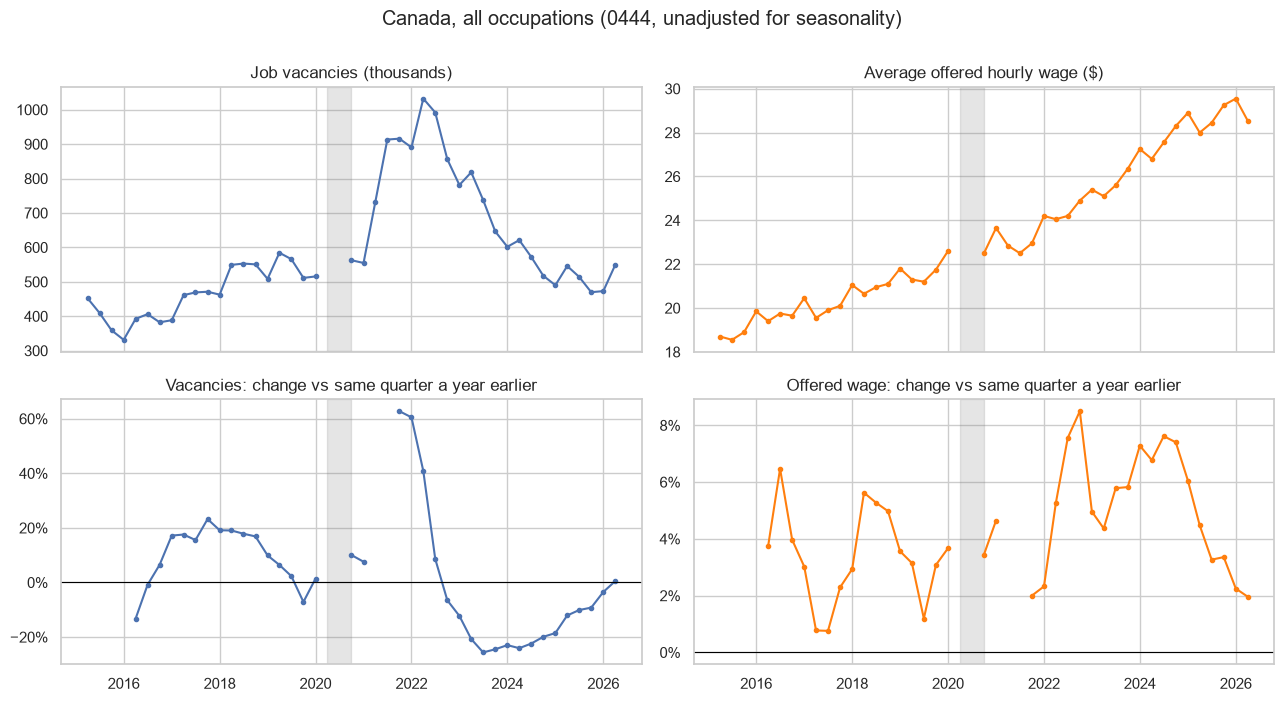

            vacancies  vacancies_yoy  offered_wage  wage_yoy
2025-01-01   490170.0         -0.185         28.90     0.061
2025-04-01   545910.0         -0.121         28.00     0.045
2025-07-01   514465.0         -0.101         28.45     0.033
2025-10-01   469840.0         -0.092         29.25     0.034
2026-01-01   473035.0         -0.035         29.55     0.022
2026-04-01   548400.0          0.005         28.55     0.020


In [9]:
tot = reliable(f444[(f444["geo_id"] == 1) & (f444["noc_id"] == 1)])
idx = QUARTERS[1:]   # D9: start at 2015-04
trend = {m: tot[tot["measure"] == m].set_index("period_start")["value"].reindex(idx)
         for m in ("job_vacancies", "offered_wage_avg")}
yoy = {m: s / s.shift(4) - 1 for m, s in trend.items()}

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
axes[0, 0].plot(idx, trend["job_vacancies"] / 1000, marker="o", ms=3)
axes[0, 0].set_title("Job vacancies (thousands)")
axes[0, 1].plot(idx, trend["offered_wage_avg"], marker="o", ms=3, color="tab:orange")
axes[0, 1].set_title("Average offered hourly wage ($)")
axes[1, 0].plot(idx, yoy["job_vacancies"], marker="o", ms=3)
axes[1, 0].set_title("Vacancies: change vs same quarter a year earlier")
axes[1, 1].plot(idx, yoy["offered_wage_avg"], marker="o", ms=3, color="tab:orange")
axes[1, 1].set_title("Offered wage: change vs same quarter a year earlier")
for ax in axes[1]:
    ax.axhline(0, color="black", lw=0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
for ax in axes.flat:
    ax.axvspan(*GAP, color="grey", alpha=0.2)
fig.suptitle("Canada, all occupations (0444, unadjusted for seasonality)", y=1.0)
fig.tight_layout()
save(fig, "06_national_trends.png")
plt.show()

recent = pd.DataFrame({"vacancies": trend["job_vacancies"], "vacancies_yoy": yoy["job_vacancies"],
                       "offered_wage": trend["offered_wage_avg"], "wage_yoy": yoy["offered_wage_avg"]}).tail(6)
print(recent.round(3).to_string())

## 7. Employee wages, 1997 to 2025 (table 0417)

Actual employee wages (average hourly wage, all occupations, full- and part-time), in **current dollars**, so the increase includes inflation. Statistics Canada notes a level shift in 2006 from processing changes, so levels before and after 2006 are not strictly comparable.

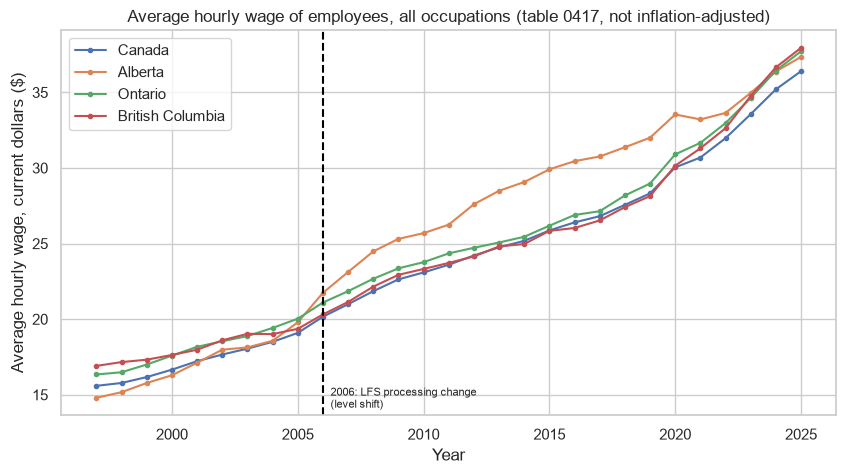

geo_name  Alberta  British Columbia  Canada  Ontario
year                                                
1997        14.80             16.91   15.59    16.34
2005        19.79             19.36   19.09    20.03
2006        21.74             20.31   20.16    21.10
2025        37.35             37.95   36.40    37.72


In [10]:
wages = f417[(f417["noc417_code"] == "00-95") & (f417["type_of_work"] == "all")
             & (f417["measure"] == "employee_wage_avg_hourly")]
wages = reliable(wages).merge(geo[["geo_id", "geo_name"]], on="geo_id")
focus = ["Canada", "Alberta", "Ontario", "British Columbia"]

fig, ax = plt.subplots(figsize=(10, 5))
for name in focus:
    part = wages[wages["geo_name"] == name].sort_values("year")
    ax.plot(part["year"], part["value"], marker="o", ms=3, label=name)
ax.axvline(2006, ls="--", color="black")
ax.text(2006.3, ax.get_ylim()[0] + 0.5, "2006: LFS processing change\n(level shift)", fontsize=8)
ax.set_ylabel("Average hourly wage, current dollars ($)")
ax.set_xlabel("Year")
ax.set_title("Average hourly wage of employees, all occupations (table 0417, not inflation-adjusted)")
ax.legend()
save(fig, "07_employee_wages_long_run.png")
plt.show()

print(wages[wages["geo_name"].isin(focus) & wages["year"].isin([1997, 2005, 2006, 2025])]
      .pivot(index="year", columns="geo_name", values="value").round(2).to_string())

## 8. Offered wages by job characteristics (0443)

Canada, all occupations, latest quarter. These are descriptive differences between groups of vacancies. They do not show that education or experience *causes* a higher offered wage, and each wage is the lowest value of an advertised range. "Seasonal" is a share of temporary vacancies, not of all vacancies.

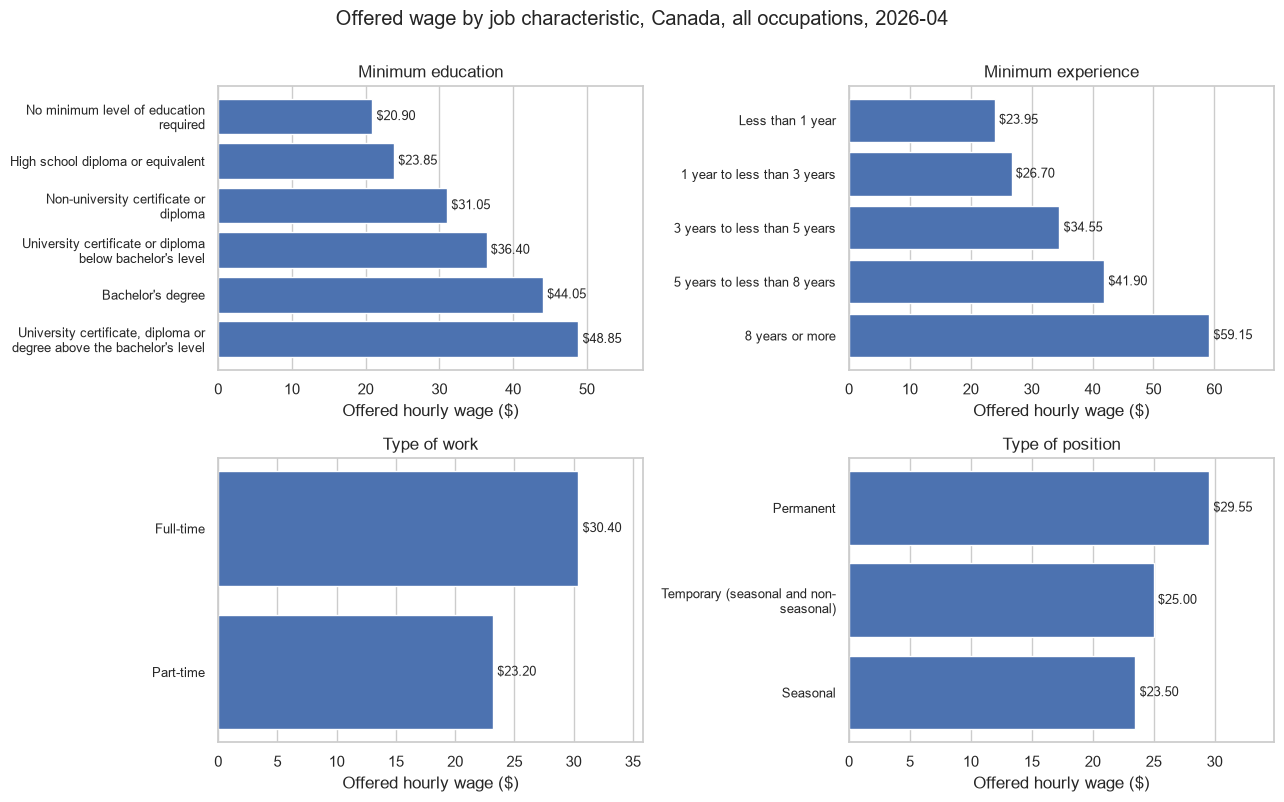

                                                               characteristic  offered_wage  vacancies  share_pct
char_id                                                                                                          
5                                      No minimum level of education required         20.90   160740.0       29.3
6                                           High school diploma or equivalent         23.85   135015.0       24.6
7                                       Non-university certificate or diploma         31.05   150310.0       27.4
10                   University certificate or diploma below bachelor's level         36.40    21120.0        3.9
12                                                          Bachelor's degree         44.05    65095.0       11.9
13       University certificate, diploma or degree above the bachelor's level         48.85    16110.0        2.9
18                                                           Less than 1 year         23

In [13]:
GROUPS = {"Minimum education": [5, 6, 7, 10, 12, 13],
          "Minimum experience": [18, 19, 20, 21, 22],
          "Type of work": [2, 3],
          "Type of position": [31, 32, 33]}

base = reliable(f443[(f443["period_start"] == LATEST) & (f443["geo_id"] == 1) & (f443["noc_id"] == 1)])
wage_c = base[base["measure"] == "offered_wage_avg"].set_index("char_id")["value"]
vac_c = base[base["measure"] == "job_vacancies"].set_index("char_id")["value"]
share_c = base[base["measure"] == "vacancy_share"].set_index("char_id")["value"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (title, ids) in zip(axes.flat, GROUPS.items()):
    vals = wage_c.reindex(ids).dropna()
    bars = ax.barh(range(len(vals)), vals.values)
    ax.bar_label(bars, fmt="$%.2f", fontsize=9, padding=3)
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels([textwrap.fill(char_title[i], 34) for i in vals.index], fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, vals.max() * 1.18)
    ax.set_xlabel("Offered hourly wage ($)")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Offered wage by job characteristic, Canada, all occupations, {LATEST:%Y-%m}", y=1.0)
fig.tight_layout()
save(fig, "08_wage_by_characteristic.png")
plt.show()

ids = [i for group in GROUPS.values() for i in group]
summary = pd.DataFrame({"characteristic": char_title.reindex(ids), "offered_wage": wage_c.reindex(ids),
                        "vacancies": vac_c.reindex(ids), "share_pct": share_c.reindex(ids)})
print(summary.to_string())

In [14]:
v = trend["job_vacancies"].dropna()
w = trend["offered_wage_avg"].dropna()
peak = v.idxmax()
after = v[v.index > peak]
print(f"Vacancies: peak {v.max():,.0f} in {peak:%Y-%m}; lowest after the peak {after.min():,.0f} "
      f"in {after.idxmin():%Y-%m}; latest {v.iloc[-1]:,.0f} in {v.index[-1]:%Y-%m}")
print(f"Offered wage: first ${w.iloc[0]:.2f} in {w.index[0]:%Y-%m}; latest ${w.iloc[-1]:.2f} in {w.index[-1]:%Y-%m}")
yv, yw = yoy["job_vacancies"].dropna(), yoy["offered_wage_avg"].dropna()
print(f"Vacancy change vs a year earlier: highest {yv.max():.1%} in {yv.idxmax():%Y-%m}; "
      f"lowest {yv.min():.1%} in {yv.idxmin():%Y-%m}; latest {yv.iloc[-1]:.1%} in {yv.index[-1]:%Y-%m}")
print(f"Offered wage change vs a year earlier: highest {yw.max():.1%} in {yw.idxmax():%Y-%m}; "
      f"lowest {yw.min():.1%} in {yw.idxmin():%Y-%m}; latest {yw.iloc[-1]:.1%} in {yw.index[-1]:%Y-%m}")

print("\nEmployee wages (0417, current dollars):")
print(wages[wages["geo_name"].isin(focus) & wages["year"].isin([1997, 2005, 2006, 2025])]
      .pivot(index="year", columns="geo_name", values="value").round(2).to_string())

print("\nHighest and lowest offered wages among Canadian unit groups:")
print(table.nlargest(5, "offered_wage")[show].to_string(index=False))
print(table.nsmallest(5, "offered_wage")[show].to_string(index=False))

Vacancies: peak 1,032,215 in 2022-04; lowest after the peak 469,840 in 2025-10; latest 548,400 in 2026-04
Offered wage: first $18.70 in 2015-04; latest $28.55 in 2026-04
Vacancy change vs a year earlier: highest 62.8% in 2021-10; lowest -25.6% in 2023-07; latest 0.5% in 2026-04
Offered wage change vs a year earlier: highest 8.5% in 2022-10; lowest 0.8% in 2017-07; latest 2.0% in 2026-04

Employee wages (0417, current dollars):
geo_name  Alberta  British Columbia  Canada  Ontario
year                                                
1997        14.80             16.91   15.59    16.34
2005        19.79             19.36   19.09    20.03
2006        21.74             20.31   20.16    21.10
2025        37.35             37.95   36.40    37.72

Highest and lowest offered wages among Canadian unit groups:
noc_code                                                                                       noc_title  offered_wage quality_grade  vacancies
   00012                         Senior manag

## What this notebook shows, and what comes next

- Coverage and quality are results in their own right: the number of occupations behind any ranking has to be reported with it.
- Everything here is descriptive and based on one source at a time. Wages from 0444 and 0417 are different measures and stay separate.
- Next (Phase 3): load the processed tables into SQL Server and reproduce the key figures there, so they can be reconciled across Python, SQL and Power BI.